Paquetes necesarios

In [11]:
import cv2  
import numpy as np
import matplotlib.pyplot as plt
import csv
import sys
!{sys.executable} -m pip install seaborn
!{sys.executable} -m pip install scikit-learn seaborn matplotlib

TAREA: Los ejemplos ilustrativos anteriores permiten saber el número de monedas presentes en la imagen ideal proporcionada. ¿Cómo determinar la cantidad de dinero presente en ella? A partir únicamente de las dimensiones, una sugerencia impicaríaj en primer término identificar de forma interactiva (por ejemplo haciendo clic en la imagen) una moneda de un valor fijo en la imagen (por ejemplo de 1€) para permitir establecer una relación entre píxeles y mo¡ilímetros. Tras obtener esa información y las dimensiones en milímetros de las distintas monedas, es factible calcular la cantidad de dinero en la imagen ideal.

Una vez resuelto el reto con la imagen ideal proporcionada, diseña un demostrador en vivo que a partir de la entrada de vídeo de la cámara, determine el dinero presente en la escena. Si bien 
no hay restricciones sobre utilizar medidas geométricas o de color, o cualquier clasificador, no deben hacer uso de modelos de aprendizaje profundo. ¿Funciona correctamente? ¿Se observan problemas?
Posibles extras serían la presencia de objetos que no son monedas y/o haya solape entre las monedas.

IMPORTANTE: No se admite el uso de modelos de aprendizaje profundo

Nota: Para establecer la correspondencia entre píxeles y milímetros, comentar que la moneda de un euro tiene un diámetro de 23.25 mm. la de 50 céntimos de 24.35, la de 20 céntimos de 22.25, etc. 



La segunda tarea plantea la clasificación de microplásticos en una imagen real. Dado que el mundo real es muy variado, las imágenes no siempre se capturan con unas condiciones de iluminación tan buenas o controladas. Ejemplo con aplicación de variantes de umbralizados ofrecidas por OpenCV sobre una imagen de muestras de microplásticos.

In [22]:
vid = cv2.VideoCapture(1)

ret = False
frame_inicial = None

while not ret:
    ret, frame_inicial = vid.read()
    cv2.waitKey(10)
    

img_ref = cv2.flip(frame_inicial, 1)
img_ref_original = img_ref.copy()

monedas_info = [
    {"nombre": "2 Euros",     "mm": 25.75, "valor": 2.00},
    {"nombre": "1 Euro",      "mm": 23.25, "valor": 1.00},
    {"nombre": "50 Centimos", "mm": 24.25, "valor": 0.50},
    {"nombre": "20 Centimos", "mm": 22.25, "valor": 0.20},
    {"nombre": "10 Centimos", "mm": 19.75, "valor": 0.10},
    {"nombre": "5 Centimos",  "mm": 21.25, "valor": 0.05},
    {"nombre": "2 Centimos",  "mm": 18.75, "valor": 0.02},
    {"nombre": "1 Centimo",   "mm": 16.25, "valor": 0.01}
]

radio_seleccionado = None
nombre_moneda_seleccionada = "Sin calibrar (Haz clic en una moneda de la mesa)"

def seleccionar_moneda(event, x, y, flags, param):
    global radio_seleccionado, nombre_moneda_seleccionada, img_ref
    if event == cv2.EVENT_LBUTTONDOWN:
        img_ref = img_ref_original.copy()
        gris_ref = cv2.cvtColor(img_ref, cv2.COLOR_BGR2GRAY)
        pimg_ref = cv2.GaussianBlur(gris_ref, (7, 7), 1.5)
        
        circs_ref = cv2.HoughCircles(
            pimg_ref, cv2.HOUGH_GRADIENT_ALT, dp=1.0, minDist=20,
            param1=250, param2=0.88, minRadius=15, maxRadius=100
        )
        
        if circs_ref is not None:
            
            for c in circs_ref[0]:
                cx, cy, r = c[0], c[1], c[2]
                distancia = np.sqrt((x - cx)**2 + (y - cy)**2)
                
                if distancia <= r:
                    radio_en_pixels = r
                    
                    print("\n--- CALIBRACIÓN DE LA MESA ---")
                    print("¿Qué moneda has pinchado en la foto de la mesa?")
                    for i, m in enumerate(monedas_info):
                        print(f"[{i}] {m['nombre']} ({m['mm']} mm)")
                    
                    opcion = input("Introduce el número de la moneda seleccionada: ")
                    try:
                        idx = int(opcion)
                        moneda_elegida = monedas_info[idx]
                        
                        radio_seleccionado = radio_en_pixels / (moneda_elegida["mm"] / 2.0)
                        
                        nombre_moneda_seleccionada = f"Calibrado con: {moneda_elegida['nombre']} ({moneda_elegida['mm']}mm)"
                        print(f"[EXITO] {nombre_moneda_seleccionada} -> Escala: {radio_seleccionado:.2f} px/mm\n")
                        
                        cv2.circle(img_ref, (int(cx), int(cy)), int(r), (0, 0, 255), 3)
                        cv2.putText(img_ref, moneda_elegida['nombre'], (int(cx) - 30, int(cy) - int(r) - 5),
                                    cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 0, 255), 2)
                        break
                    except Exception:
                        print("[ERROR] Opción no válida. Vuelve a hacer clic.")

cv2.namedWindow('Imagen Referencia')
cv2.setMouseCallback('Imagen Referencia', seleccionar_moneda)

print("[INFO] Ventana abierta. Haz clic sobre una moneda en la foto de la mesa y mira la consola de Python.")


while(True):      

    ret, frame = vid.read()
    
    if ret: 
        
        frame = cv2.flip(frame, 1)  
        gris = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
        pimg = cv2.GaussianBlur(gris, (7, 7), 1.5)
        
        circ = cv2.HoughCircles(
                pimg,  # imagen 
                cv2.HOUGH_GRADIENT_ALT,  # tipo de detección
                dp=1,
                minDist=40, # distancia mínima entre círculos
                param1=250, # valor del gradiente
                param2=0.91, # umbral acumulador
                minRadius=18,  # radio mínimo
                maxRadius=65,  # radio máximo
            )


        img_cont = np.zeros(frame.shape, dtype=np.uint8)
        num_monedas = 0
        dinero_total = 0.0
        
        if circ is not None:
            
            monedas = np.uint16(np.around(circ[0]))
            num_monedas = len(monedas)
            
            for det in circ[0]:
                x_coor, y_coor, det_radio = det
                
                cv2.circle(frame, (int(x_coor), int(y_coor)),
                        int(det_radio), (0, 255, 0), 2)
                cv2.circle(img_cont, (int(x_coor), int(y_coor)),
                        int(det_radio), (255, 255, 255), -1)
                
                if radio_seleccionado is not None:
                
                    diametro_mm = (det_radio * 2) / radio_seleccionado
                    
                    moneda_detectada = min(
                        monedas_info, 
                        key=lambda m: abs((m["mm"]**2) - (diametro_mm**2))
                    )
                    
                    dinero_total += moneda_detectada["valor"]
                    cv2.putText(frame, f"{moneda_detectada['nombre']}", 
                                (int(x_coor) - 35, int(y_coor) - int(det_radio) - 10),
                                cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 255, 255), 2)
                    
                    
        cv2.putText(frame, f"Monedas actuales: {num_monedas}", (10, 30),
            cv2.FONT_HERSHEY_SIMPLEX, 0.7, (0, 255, 255), 2)
        cv2.putText(frame, f"Dinero total: {dinero_total:.2f} €", (10, 60),
            cv2.FONT_HERSHEY_SIMPLEX, 0.5, (255, 200, 0), 2)
        

        cv2.imshow('Imagen Referencia', img_ref)
        cv2.imshow('Cam', frame)   
        cv2.imshow('Rellenos', img_cont)
        
    if cv2.waitKey(20) == 27:
        break
vid.release()
# Destruye ventanas
cv2.destroyAllWindows()


[INFO] Ventana abierta. Haz clic sobre una moneda en la foto de la mesa y mira la consola de Python.

--- CALIBRACIÓN DE LA MESA ---
¿Qué moneda has pinchado en la foto de la mesa?
[0] 2 Euros (25.75 mm)
[1] 1 Euro (23.25 mm)
[2] 50 Centimos (24.25 mm)
[3] 20 Centimos (22.25 mm)
[4] 10 Centimos (19.75 mm)
[5] 5 Centimos (21.25 mm)
[6] 2 Centimos (18.75 mm)
[7] 1 Centimo (16.25 mm)
[EXITO] Calibrado con: 50 Centimos (24.25mm) -> Escala: 3.23 px/mm


--- CALIBRACIÓN DE LA MESA ---
¿Qué moneda has pinchado en la foto de la mesa?
[0] 2 Euros (25.75 mm)
[1] 1 Euro (23.25 mm)
[2] 50 Centimos (24.25 mm)
[3] 20 Centimos (22.25 mm)
[4] 10 Centimos (19.75 mm)
[5] 5 Centimos (21.25 mm)
[6] 2 Centimos (18.75 mm)
[7] 1 Centimo (16.25 mm)
[EXITO] Calibrado con: 50 Centimos (24.25mm) -> Escala: 3.23 px/mm



TAREA: La tarea consiste en extraer características (geométricas y/o visuales) de las tres imágenes completas de partida, y *aprender* patrones que permitan identificar las partículas en nuevas imágenes. Para ello se proporciona como imagen de test *MPs_test.jpg* y sus correpondientes anotaciones *MPs_test_bbs.csv* con la que deben obtener las métricas para su propuesta de clasificación de microplásticos, además de la matriz de confusión. La matriz de confusión permitirá mostrar para cada clase el número de muestras que se clasifican correctamente de dicha clase, y el número de muestras que se clasifican incorrectamente como perteneciente a una de las otras dos clases. De nuevo, no deben hacer uso de modelos de aprendizaje `profunfop ni poara segmentar,  ni para clasificar.

En el trabajo [SMACC: A System for Microplastics Automatic Counting and Classification](https://doi.org/10.1109/ACCESS.2020.2970498), las características geométricas utilizadas fueron:

- Área en píxeles
- Perímetro en píxeles
- Compacidad (relación entre el cuadrado del perímetro y el área de la partícula)
- Relación del área de la partícula con la del contenedor
- Relación del ancho y el alto del contenedor
- Relación entre los ejes de la elipse ajustada
- Definido el centroide, relación entre las distancias menor y mayor al contorno

Si no se quedan satisfechos con la segmentación obtenida, es el mundo real, también en el README comento técnicas recientes de segmentación, que podrían despertar su curiosidad.

IMPORTANTE: No se admite el uso de modelos de aprendizaje profundo

In [9]:
def extraer_patrones(ruta_imagen):
    # Leer imagen en escala de grises
    img = cv2.imread(ruta_imagen, cv2.IMREAD_GRAYSCALE)
    
    # Umbralizado de Otsu
    _, umbral = cv2.threshold(img, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
    
    # Buscar los contornos de cada partícula
    contornos, _ = cv2.findContours(umbral, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    
    compacidades = []
    relaciones_aspecto = []
    
    for c in contornos:
        area = cv2.contourArea(c)
        perimetro = cv2.arcLength(c, True)
        
        # Filtramos ruido
        if area > 50:
            # Compacidad (Perímetro al cuadrado / Área)
            compacidad = (perimetro ** 2) / area
            compacidades.append(compacidad)
            
            # Relación de aspecto (Ancho / Alto)
            x, y, w, h = cv2.boundingRect(c)
            
            eje_mayor = max(w, h)
            eje_menor = min(w, h)
            aspecto = eje_mayor / float(eje_menor)
            relaciones_aspecto.append(aspecto)
            
    return np.mean(compacidades), np.mean(relaciones_aspecto)

# 3 imágenes de entrenamiento
comp_pel, asp_pel = extraer_patrones('PEL.png')
print(f"PEL -> Compacidad: {comp_pel:.2f} | Aspecto: {asp_pel:.2f}")

comp_fra, asp_fra = extraer_patrones('FRA.png')
print(f"FRA -> Compacidad: {comp_fra:.2f} | Aspecto: {asp_fra:.2f}")

comp_tar, asp_tar = extraer_patrones('TAR.png')
print(f"TAR -> Compacidad: {comp_tar:.2f} | Aspecto: {asp_tar:.2f}")

PEL -> Compacidad: 19.56 | Aspecto: 1.34
FRA -> Compacidad: 57.72 | Aspecto: 1.59
TAR -> Compacidad: 17.37 | Aspecto: 1.12


In [6]:
def clasificar_particula(compacidad, aspecto):

    # Si la compacidad es muy alta, es un borde muy irregular
    if compacidad > 35.0:
        return "FRA"
    
    # Si la compacidad es baja, miramos si es ovalado
    elif aspecto > 1.22:
        return "PEL"
    
    # Si la compacidad es baja y es circular
    else:
        return "TAR"

In [7]:
y_true = []
y_pred = []

img_gris = cv2.imread('MPs_test.jpg', cv2.IMREAD_GRAYSCALE)

with open('MPs_test_bbs.csv', newline="") as file:
    reader = csv.DictReader(file)
    
    for row in reader:
        # Guardamos la etiqueta correcta
        etiqueta_real = row["label"]
        y_true.append(etiqueta_real)
        
        x_min, y_min, x_max, y_max = map(int, [row["x_min"], row["y_min"], row["x_max"], row["y_max"]])

        recorte = img_gris[y_min:y_max, x_min:x_max]
        
        _, umbral = cv2.threshold(recorte, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
        contornos, _ = cv2.findContours(umbral, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        
        # Valores por defecto
        compacidad = 0
        aspecto = 1.0
        
        # Si encontramos manchas, cogemos la más grande
        if len(contornos) > 0:
            c = max(contornos, key=cv2.contourArea)
            area = cv2.contourArea(c)
            perimetro = cv2.arcLength(c, True)
            
            # Calculamos la geometría de este recorte específico
            if area > 0: 
                compacidad = (perimetro ** 2) / area
                x, y, w, h = cv2.boundingRect(c)
                
                eje_mayor = max(w, h)
                eje_menor = max(min(w, h), 1)
                aspecto = eje_mayor / float(eje_menor)
        
        etiqueta_predicha = clasificar_particula(compacidad, aspecto)
        
        # Guardamos la respuesta de nuestro programa
        y_pred.append(etiqueta_predicha)

print(f"Total de partículas analizadas: {len(y_true)}")

Total de partículas analizadas: 120


Accuracy = 0.475
Precision = 0.523
Recall = 0.475
F1 Score = 0.490


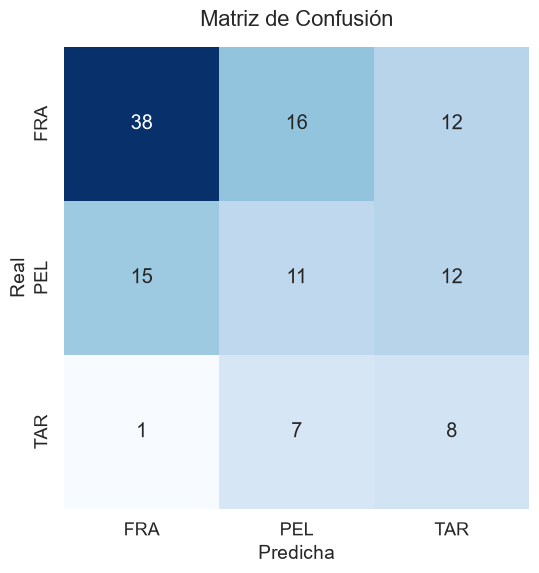

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Definimos las clases usadas
clases = ["FRA", "PEL", "TAR"]

accuracy = accuracy_score(y_true, y_pred)
precision = precision_score(y_true, y_pred, average='weighted', zero_division=0)
recall = recall_score(y_true, y_pred, average='weighted', zero_division=0)
f1score = f1_score(y_true, y_pred, average='weighted', zero_division=0)

print(f"Accuracy = {accuracy:.3f}")
print(f"Precision = {precision:.3f}")
print(f"Recall = {recall:.3f}")
print(f"F1 Score = {f1score:.3f}")

# Generación de la Matriz de Confusión
conf_matrix = confusion_matrix(y_true, y_pred, labels=clases)

plt.figure(figsize=(6,6))
sns.set_theme(font_scale=1.2) 

ax = sns.heatmap(
        conf_matrix, 
        annot=True,      
        fmt='d',         
        cbar=False,      
        cmap='Blues',    
        xticklabels=clases, 
        yticklabels=clases
    )

label_font = {'size':'14'}
ax.set_xlabel("Predicha", fontdict=label_font)
ax.set_ylabel("Real", fontdict=label_font)
plt.title("Matriz de Confusión", fontsize=16, pad=15)
plt.show()